In [1]:
import pathlib

import pandas as pd
from matplotlib import pyplot as plt

import el_hd_plasticity.connectomics as cn
from el_hd_plasticity.connectomics import connectivity, datasets, plotting

plt.rcParams['pdf.fonttype'] = 42

%load_ext autoreload
%autoreload 2
%matplotlib inline

figfolder = pathlib.Path('/media/mplitt/SSD_storage/fig_scratch/EL_connectomics')
figfolder.mkdir(parents=True, exist_ok=True)

## Datasets

The hemibrain and the male CNS (MCNS) are read from neuPrint. FAFB and BANC (flywire) are added below once their tables are available.

In [2]:
all_datasets = {
    'hemibrain': datasets.NeuprintDataset('hemibrain', 'hemibrain:v1.2.1'),
    'MCNS': datasets.NeuprintDataset('MCNS', 'male-cns:v0.9'),
}

FAFB and BANC (flywire) come from Codex, which serves static tables: the first call downloads the table of connections and the table of cell
types of each dataset (cached in `~/.cache/el_hd_plasticity/codex`). The Codex API token is read from the `CODEX_API_TOKEN` environment variable
(copy it from https://codex.flywire.ai/account); the available data products are listed at https://codex.flywire.ai/download?dataset=fafb.
Codex's `connections_princeton` only contains connections of at least 5 synapses, so weights are lower than in the neuPrint datasets, which are
analysed with connections of at least 3 synapses.

In [3]:
if cn.params.CODEX_TOKEN:
    codex = datasets.CodexClient()
    for name, dataset in (('FAFB', 'fafb'), ('BANC', 'banc')):
        all_datasets[name] = datasets.load_codex(name, dataset, client=codex)
else:
    print('CODEX_API_TOKEN is not set: comparing the neuPrint datasets only')

In [4]:
# the cell types have to follow the hemibrain naming (EL, EPG, ER4d, ER2_a, ...)
for name, dataset in all_datasets.items():
    print(name, dataset.neurons(['EL', 'EPG', 'ER4d', 'ER2.*'])['type'].value_counts().to_dict())

hemibrain {'EPG': 46, 'ER4d': 25, 'ER2_c': 21, 'EL': 18, 'ER2_a': 9, 'ER2_d': 6, 'ER2_b': 6}
MCNS {'EPG': 46, 'ER4d': 26, 'ER2_c': 20, 'EL': 18, 'ER2_a': 12, 'ER2_d': 5, 'ER2_b': 4}
FAFB {'EPG': 47, 'ER2': 43, 'ER4d': 24, 'EL': 17}
BANC {'EPG': 45, 'ER2_c': 28, 'ER4d': 28, 'EL': 18, 'ER2_a': 11, 'ER2_d': 4, 'ER2_b': 2}


## Connectivity between EL, EPG and ER2/4d

In [5]:
type_table = connectivity.compare_datasets(all_datasets, connectivity.dataset_type_connectivity)
type_table

  0%|          | 0/1 [00:00<?, ?it/s]

0it [00:00, ?it/s]

  0%|          | 0/14 [00:00<?, ?it/s]

  0%|          | 0/14 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

0it [00:00, ?it/s]

  0%|          | 0/14 [00:00<?, ?it/s]

  0%|          | 0/14 [00:00<?, ?it/s]

,type_pre,type_post,weight,relative_weight,pcnt_output,nrn_weight,dataset
0,EL,EPG,5634,0.035715,0.383161,122.478261,hemibrain
1,EPG,EL,9311,0.122442,0.812762,517.277778,hemibrain
2,EL,ER2/4d,12145,0.120118,0.825966,181.268657,hemibrain
3,EPG,ER2/4d,2187,0.021630,0.190904,32.641791,hemibrain
4,ER2/4d,EL,12424,0.163379,0.383895,690.222222,hemibrain
5,ER2/4d,EPG,34026,0.215697,1.051386,739.695652,hemibrain
6,EL,EPG,3464,0.018677,0.453878,75.304348,MCNS
7,EPG,EL,8666,0.124565,0.637769,481.444444,MCNS
8,EL,ER2/4d,6671,0.056034,0.874083,99.567164,MCNS
9,EPG,ER2/4d,5397,0.045333,0.397189,80.552239,MCNS


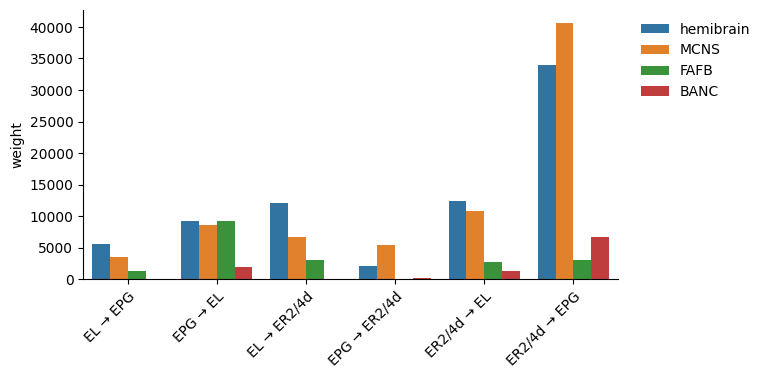

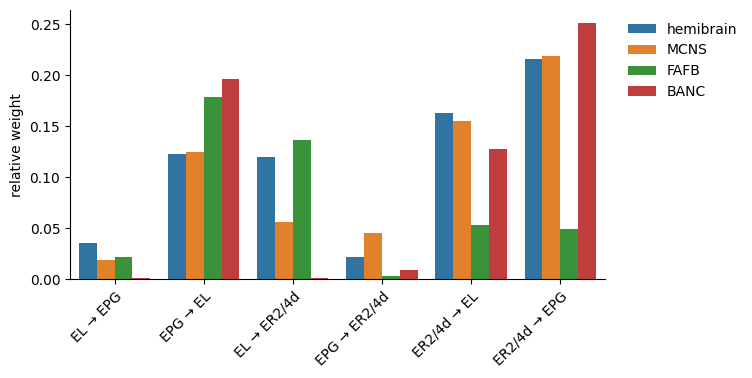

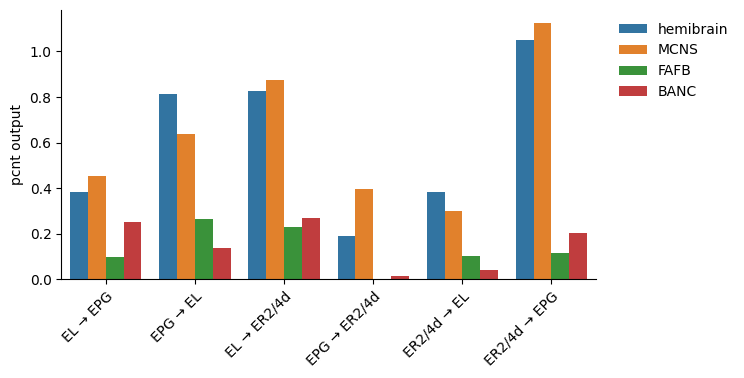

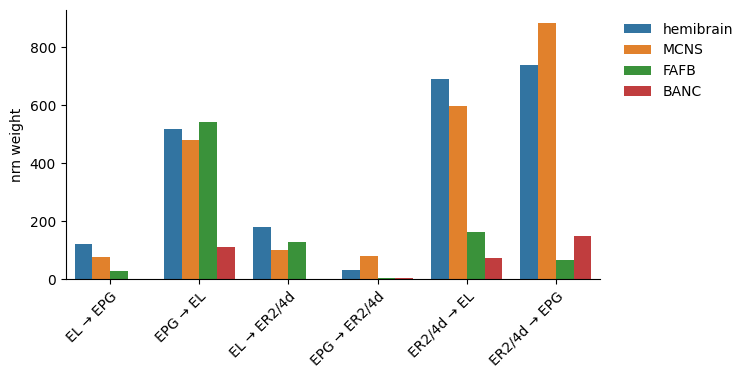

In [6]:
for edge_attr in ('weight', 'relative_weight', 'pcnt_output', 'nrn_weight'):
    fig, ax = plotting.plot_connectivity_comparison(type_table, edge_attr)
    # fig.savefig(figfolder / f'connectivity_comparison_{edge_attr}.pdf', bbox_inches='tight')

## Inputs onto ER neurons

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/11 [00:00<?, ?it/s]

  0%|          | 0/24 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/12 [00:00<?, ?it/s]

  0%|          | 0/26 [00:00<?, ?it/s]

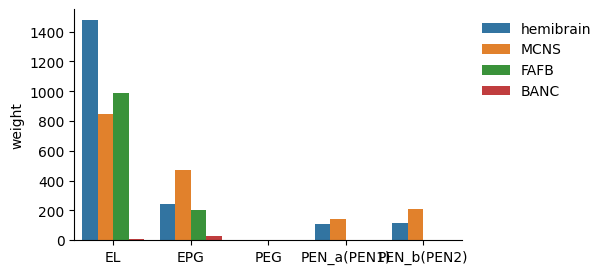

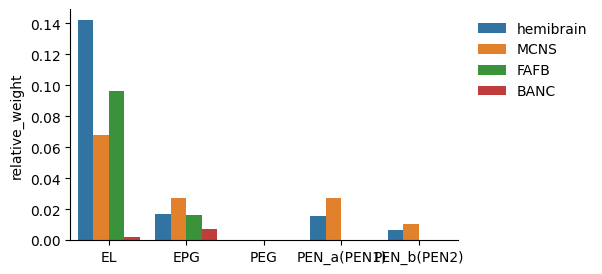

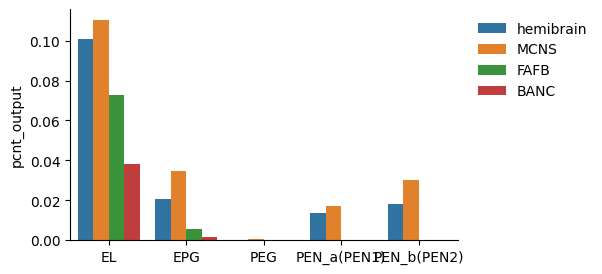

In [7]:
er_inputs = {name: connectivity.er_input_connections(dataset) for name, dataset in all_datasets.items()}
for weight_col in ('weight', 'relative_weight', 'pcnt_output'):
    fig, ax = plotting.plot_input_comparison(connectivity.er_input_marginals(er_inputs, weight_col), ylabel=weight_col)